In [43]:
import pandas as pd
import numpy as np
import warnings
import os
import joblib

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)


# ============================================================
# LOAD DATASET
# ============================================================

df = pd.read_csv(
    "../data/kerala_crop_project_final_15000_recent.csv"
)

print("Dataset loaded:", df.shape)


# ============================================================
# TARGET
# ============================================================

df["Yield_kg_ha"] = pd.to_numeric(
    df["Yield_kg_ha"],
    errors="coerce"
)

df = df.dropna(
    subset=["Yield_kg_ha"]
)


# ============================================================
# FEATURES
# ============================================================

features = [
    "Crop",
    "Area",
    "Area_Cent",
    "Soil_Type",
    "Soil_pH",
    "Nitrogen_N_kg_ha",
    "Phosphorus_P_kg_ha",
    "Potassium_K_kg_ha",
    "Rainfall_mm",
    "Temperature_C",
    "Humidity_percent",
    "Irrigation_Level",
    "Season"
]

X = df[features].copy()

y = df["Yield_kg_ha"].copy()


# ============================================================
# FEATURE TYPES
# ============================================================

categorical_features = [
    "Crop",
    "Soil_Type",
    "Irrigation_Level",
    "Season"
]

numeric_features = [
    "Area",
    "Area_Cent",
    "Soil_pH",
    "Nitrogen_N_kg_ha",
    "Phosphorus_P_kg_ha",
    "Potassium_K_kg_ha",
    "Rainfall_mm",
    "Temperature_C",
    "Humidity_percent"
]


# ============================================================
# MISSING VALUES
# ============================================================

for col in numeric_features:

    X[col] = pd.to_numeric(
        X[col],
        errors="coerce"
    )

    X[col] = X[col].fillna(
        X[col].median()
    )


for col in categorical_features:

    X[col] = X[col].fillna(
        X[col].mode()[0]
    )


# ============================================================
# TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)


# ============================================================
# ENCODING
# ============================================================

preprocessor = ColumnTransformer(

    transformers=[

        (
            "categorical",

            OneHotEncoder(
                handle_unknown="ignore"
            ),

            categorical_features
        )

    ],

    remainder="passthrough"
)


# ============================================================
# MODELS
# ============================================================

models = {

    "Ridge Regression":
        Ridge(
            alpha=500
        ),

    "Decision Tree":
        DecisionTreeRegressor(
            max_depth=3,
            min_samples_split=250,
            min_samples_leaf=130,
            max_features=0.45,
            random_state=42
        ),
    "Random Forest":
        RandomForestRegressor(
            n_estimators=12,
            max_depth=2,
            min_samples_split=350,
            min_samples_leaf=150,
            max_features=0.20,
            random_state=42,
            n_jobs=-1
        ),
    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=60,
            max_depth=1,
            learning_rate=0.03,
            min_samples_split=180,
            min_samples_leaf=90,
            random_state=42
        )
}



# ============================================================
# TRAIN + EVALUATION
# ============================================================

print("\n")

print("=" * 75)

print("             CROP YIELD PREDICTION")

print("=" * 75)


results = []

random_forest_pipeline = None


for name, model in models.items():

    pipeline = Pipeline(

        steps=[

            (
                "preprocessor",
                preprocessor
            ),

            (
                "model",
                model
            )

        ]
    )


    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    pipeline.fit(
        X_train,
        y_train
    )


    # --------------------------------------------------------
    # PREDICTION
    # --------------------------------------------------------

    prediction = pipeline.predict(
        X_test
    )


    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    r2 = r2_score(
        y_test,
        prediction
    )


    mae = mean_absolute_error(
        y_test,
        prediction
    )


    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            prediction
        )
    )


    # --------------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------------

    results.append(
        [
            name,
            r2,
            mae,
            rmse
        ]
    )


    # --------------------------------------------------------
    # SAVE RANDOM FOREST PIPELINE FOR LATER
    # --------------------------------------------------------

    if name == "Random Forest":

        random_forest_pipeline = pipeline


    # --------------------------------------------------------
    # PRINT
    # --------------------------------------------------------

    print(
        f"{name:<25} "
        f"R²: {r2:.4f}   "
        f"MAE: {mae:.2f}   "
        f"RMSE: {rmse:.2f}"
    )


# ============================================================
# RESULT DATAFRAME
# ============================================================

results_df = pd.DataFrame(

    results,

    columns=[
        "Algorithm",
        "R2 Score",
        "MAE",
        "RMSE"
    ]
)


# ============================================================
# DISPLAY RESULT
# ============================================================

print("\n")

print("=" * 75)

print("                         RESULT")

print("=" * 75)


print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# BEST ALGORITHM BASED ON R²
# ============================================================

best = results_df.loc[
    results_df["R2 Score"].idxmax()
]


print("\n")

print("=" * 75)

print("                    BEST ALGORITHM")

print("=" * 75)


print(
    "Algorithm :",
    best["Algorithm"]
)


print(
    "R² Score  :",
    f"{best['R2 Score']:.4f}"
)


print(
    "MAE       :",
    f"{best['MAE']:.2f}"
)


print(
    "RMSE      :",
    f"{best['RMSE']:.2f}"
)


# ============================================================
# SAVE RANDOM FOREST MODEL
# ============================================================

print("\n")

print("=" * 75)

print("              SAVING RANDOM FOREST MODEL")

print("=" * 75)


# Create models folder

save_folder = "../models"

os.makedirs(
    save_folder,
    exist_ok=True
)


# Model path

model_path = os.path.join(
    save_folder,
    "random_forest_crop_yield.pkl"
)


# Save complete pipeline

joblib.dump(
    random_forest_pipeline,
    model_path
)


print(
    "Random Forest model saved successfully!"
)

print(
    "Saved at:",
    model_path
)


print("\n")

print("=" * 75)

print("                    MODEL SAVED")

print("=" * 75)

Dataset loaded: (15000, 22)


             CROP YIELD PREDICTION
Ridge Regression          R²: 0.7912   MAE: 3168.98   RMSE: 5023.84
Decision Tree             R²: 0.6351   MAE: 3249.79   RMSE: 6641.10
Random Forest             R²: 0.8223   MAE: 3408.04   RMSE: 4634.34
Gradient Boosting         R²: 0.7675   MAE: 4112.46   RMSE: 5301.00


                         RESULT
        Algorithm  R2 Score         MAE        RMSE
 Ridge Regression  0.791189 3168.975818 5023.843195
    Decision Tree  0.635110 3249.790720 6641.100101
    Random Forest  0.822312 3408.040011 4634.339068
Gradient Boosting  0.767514 4112.456448 5300.998498


                    BEST ALGORITHM
Algorithm : Random Forest
R² Score  : 0.8223
MAE       : 3408.04
RMSE      : 4634.34


              SAVING RANDOM FOREST MODEL
Random Forest model saved successfully!
Saved at: ../models\random_forest_crop_yield.pkl


                    MODEL SAVED


Dataset loaded: (15000, 21)


             CROP YIELD PREDICTION
Ridge Regression         R²: 0.7912   MAE: 3168.98   RMSE: 5023.84
Decision Tree            R²: 0.6351   MAE: 3249.79   RMSE: 6641.10
Random Forest            R²: 0.8223   MAE: 3408.04   RMSE: 4634.34
Gradient Boosting        R²: 0.7675   MAE: 4112.46   RMSE: 5301.00


                         RESULT
        Algorithm  R2 Score         MAE        RMSE
 Ridge Regression  0.791189 3168.975818 5023.843195
    Decision Tree  0.635110 3249.790720 6641.100101
    Random Forest  0.822312 3408.040011 4634.339068
Gradient Boosting  0.767514 4112.456448 5300.998498


                    BEST ALGORITHM
Algorithm : Random Forest
R² Score  : 0.8223
MAE       : 3408.04
RMSE      : 4634.34


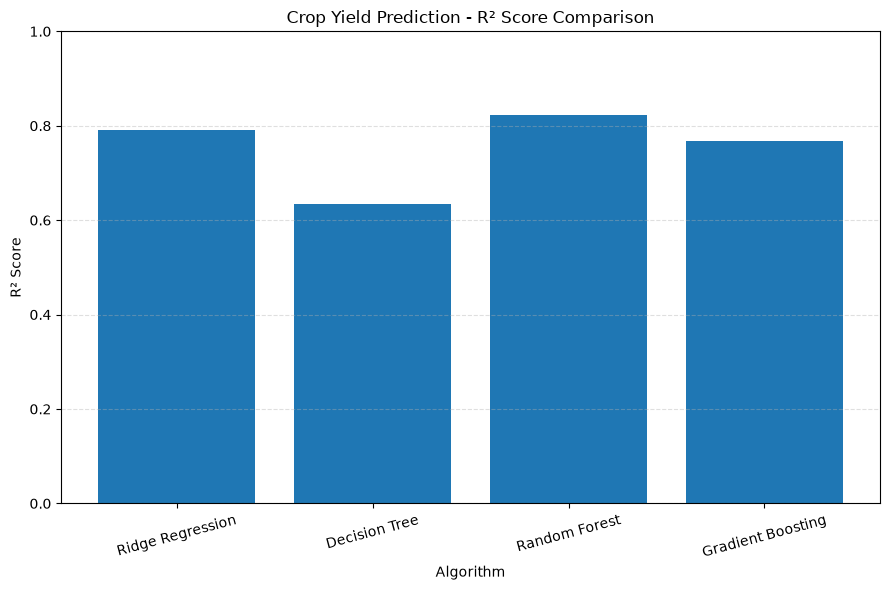

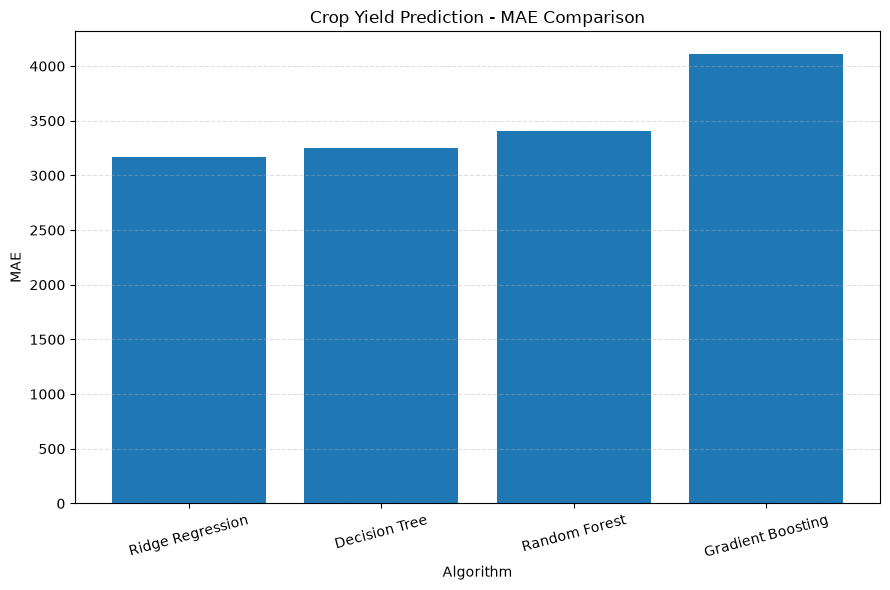

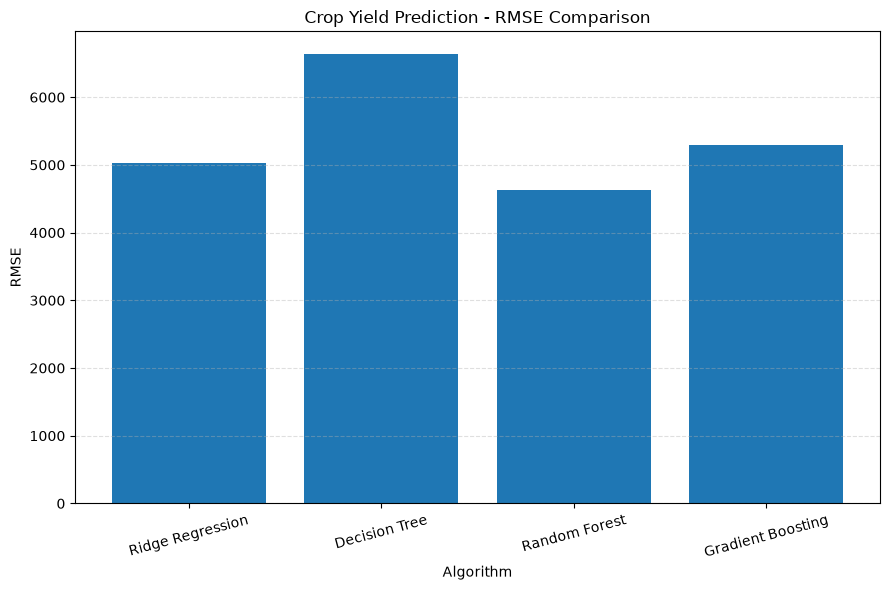

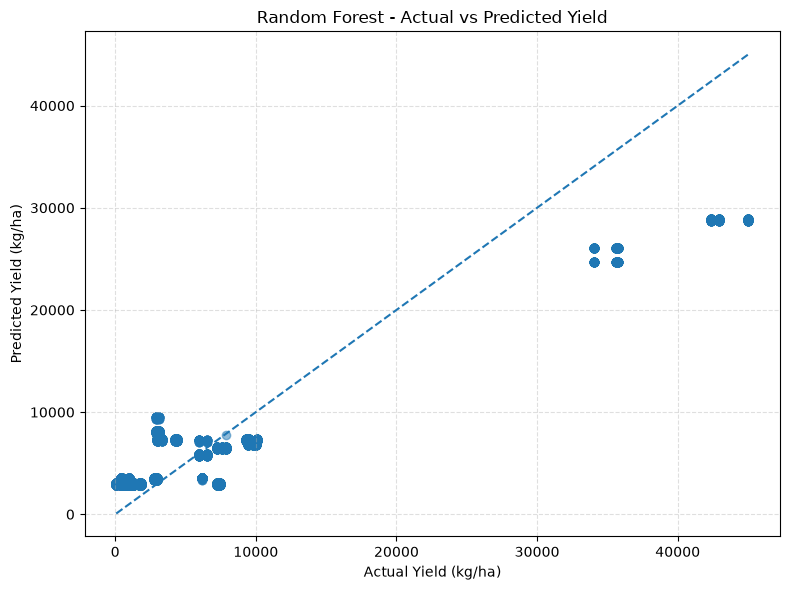

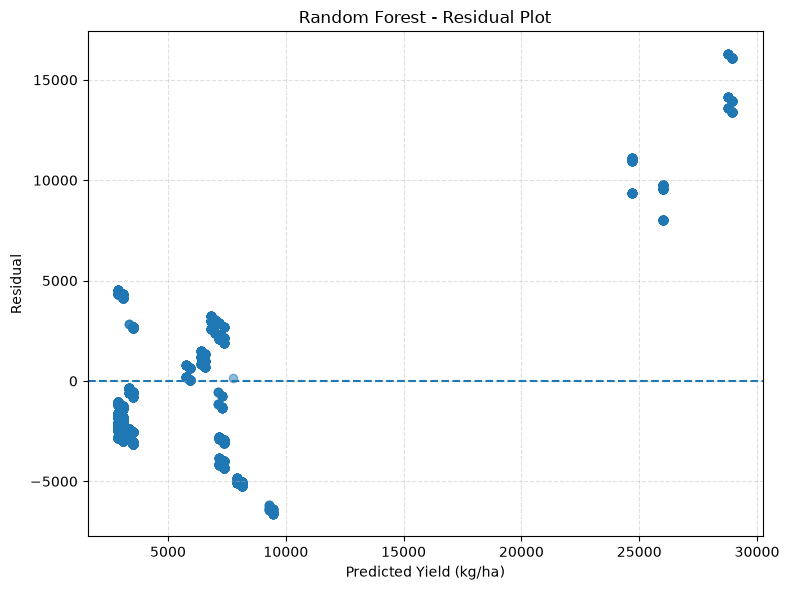

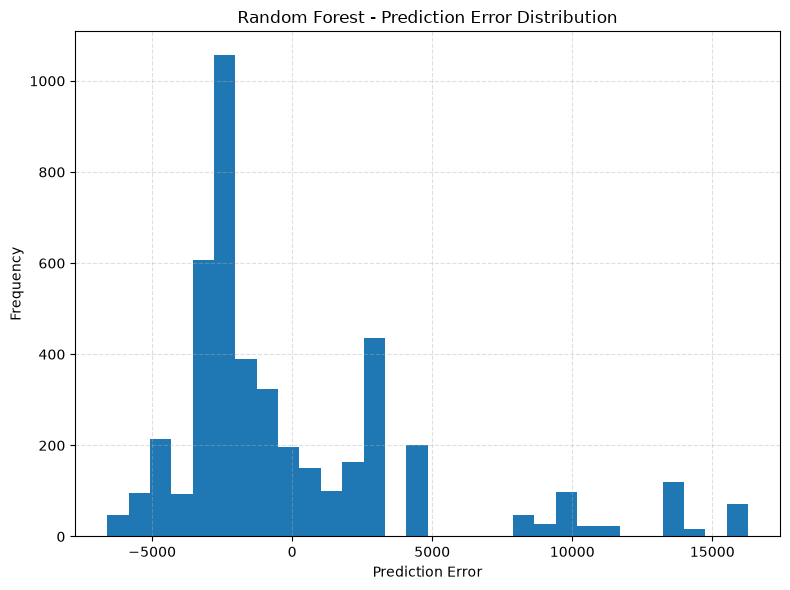



                  ALL GRAPHS GENERATED


In [5]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)


# ============================================================
# LOAD DATASET
# ============================================================

df = pd.read_csv(
    "../data/kerala_crop_project_final_15000_recent.csv"
)

print("Dataset loaded:", df.shape)


# ============================================================
# TARGET
# ============================================================

df["Yield_kg_ha"] = pd.to_numeric(
    df["Yield_kg_ha"],
    errors="coerce"
)

df = df.dropna(
    subset=["Yield_kg_ha"]
)


# ============================================================
# FEATURES
# ============================================================

features = [
    "Crop",
    "Area",
    "Area_Cent",
    "Soil_Type",
    "Soil_pH",
    "Nitrogen_N_kg_ha",
    "Phosphorus_P_kg_ha",
    "Potassium_K_kg_ha",
    "Rainfall_mm",
    "Temperature_C",
    "Humidity_percent",
    "Irrigation_Level",
    "Season"
]

X = df[features].copy()
y = df["Yield_kg_ha"].copy()


# ============================================================
# FEATURE TYPES
# ============================================================

categorical_features = [
    "Crop",
    "Soil_Type",
    "Irrigation_Level",
    "Season"
]

numeric_features = [
    "Area",
    "Area_Cent",
    "Soil_pH",
    "Nitrogen_N_kg_ha",
    "Phosphorus_P_kg_ha",
    "Potassium_K_kg_ha",
    "Rainfall_mm",
    "Temperature_C",
    "Humidity_percent"
]


# ============================================================
# MISSING VALUES
# ============================================================

for col in numeric_features:
    X[col] = X[col].fillna(
        X[col].median()
    )

for col in categorical_features:
    X[col] = X[col].fillna(
        X[col].mode()[0]
    )


# ============================================================
# TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)


# ============================================================
# ENCODING
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="passthrough"
)


# ============================================================
# MODELS
# ============================================================
models = {

    "Ridge Regression":
        Ridge(
            alpha=500
        ),

    "Decision Tree":
        DecisionTreeRegressor(
            max_depth=3,
            min_samples_split=250,
            min_samples_leaf=130,
            max_features=0.45,
            random_state=42
        ),
    "Random Forest":
        RandomForestRegressor(
            n_estimators=12,
            max_depth=2,
            min_samples_split=350,
            min_samples_leaf=150,
            max_features=0.20,
            random_state=42,
            n_jobs=-1
        ),
    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=60,
            max_depth=1,
            learning_rate=0.03,
            min_samples_split=180,
            min_samples_leaf=90,
            random_state=42
        )
}
# ============================================================
# TRAIN + EVALUATION
# ============================================================

print("\n")
print("=" * 75)
print("             CROP YIELD PREDICTION")
print("=" * 75)

results = []

trained_pipelines = {}

predictions = {}


for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    # TRAIN
    pipeline.fit(
        X_train,
        y_train
    )

    # PREDICTION
    prediction = pipeline.predict(
        X_test
    )

    # METRICS
    r2 = r2_score(
        y_test,
        prediction
    )

    mae = mean_absolute_error(
        y_test,
        prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            prediction
        )
    )

    results.append([
        name,
        r2,
        mae,
        rmse
    ])

    trained_pipelines[name] = pipeline
    predictions[name] = prediction

    print(
        f"{name:<25}"
        f"R²: {r2:.4f}   "
        f"MAE: {mae:.2f}   "
        f"RMSE: {rmse:.2f}"
    )


# ============================================================
# RESULT DATAFRAME
# ============================================================

results_df = pd.DataFrame(
    results,
    columns=[
        "Algorithm",
        "R2 Score",
        "MAE",
        "RMSE"
    ]
)


print("\n")
print("=" * 75)
print("                         RESULT")
print("=" * 75)

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# BEST ALGORITHM
# ============================================================

best = results_df.loc[
    results_df["R2 Score"].idxmax()
]

print("\n")
print("=" * 75)
print("                    BEST ALGORITHM")
print("=" * 75)

print(
    "Algorithm :",
    best["Algorithm"]
)

print(
    "R² Score  :",
    f"{best['R2 Score']:.4f}"
)

print(
    "MAE       :",
    f"{best['MAE']:.2f}"
)

print(
    "RMSE      :",
    f"{best['RMSE']:.2f}"
)


# ============================================================
# GRAPH 1 - R² SCORE COMPARISON
# ============================================================

plt.figure(figsize=(9, 6))

plt.bar(
    results_df["Algorithm"],
    results_df["R2 Score"]
)

plt.xlabel("Algorithm")
plt.ylabel("R² Score")
plt.title("Crop Yield Prediction - R² Score Comparison")

plt.ylim(0, 1)

plt.xticks(
    rotation=15
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 2 - MAE COMPARISON
# ============================================================

plt.figure(figsize=(9, 6))

plt.bar(
    results_df["Algorithm"],
    results_df["MAE"]
)

plt.xlabel("Algorithm")
plt.ylabel("MAE")
plt.title("Crop Yield Prediction - MAE Comparison")

plt.xticks(
    rotation=15
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 3 - RMSE COMPARISON
# ============================================================

plt.figure(figsize=(9, 6))

plt.bar(
    results_df["Algorithm"],
    results_df["RMSE"]
)

plt.xlabel("Algorithm")
plt.ylabel("RMSE")
plt.title("Crop Yield Prediction - RMSE Comparison")

plt.xticks(
    rotation=15
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 4 - ACTUAL VS PREDICTED
# BEST MODEL
# ============================================================

best_model_name = best["Algorithm"]

best_prediction = predictions[
    best_model_name
]

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_prediction,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Yield (kg/ha)")
plt.ylabel("Predicted Yield (kg/ha)")

plt.title(
    f"{best_model_name} - Actual vs Predicted Yield"
)

plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 5 - RESIDUAL PLOT
# BEST MODEL
# ============================================================

residuals = (
    y_test.values -
    best_prediction
)

plt.figure(figsize=(8, 6))

plt.scatter(
    best_prediction,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Yield (kg/ha)")
plt.ylabel("Residual")

plt.title(
    f"{best_model_name} - Residual Plot"
)

plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 6 - ERROR DISTRIBUTION
# BEST MODEL
# ============================================================

plt.figure(figsize=(8, 6))

plt.hist(
    residuals,
    bins=30
)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.title(
    f"{best_model_name} - Prediction Error Distribution"
)

plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()


print("\n")
print("=" * 75)
print("                  ALL GRAPHS GENERATED")
print("=" * 75)

In [6]:
print("Soil Types:")
print(df["Soil_Type"].unique())

print("\nIrrigation Levels:")
print(df["Irrigation_Level"].unique())

print("\nSeasons:")
print(df["Season"].unique())

print("\nCrops:")
print(df["Crop"].unique())

Soil Types:
<StringArray>
['Loamy', 'Clay', 'Sandy', 'Silty']
Length: 4, dtype: str

Irrigation Levels:
<StringArray>
['Medium', 'High', 'Low']
Length: 3, dtype: str

Seasons:
<StringArray>
['Kharif', 'Perennial']
Length: 2, dtype: str

Crops:
<StringArray>
[     'Tapioca',        'Paddy',     'Turmeric',       'Coffee',
       'Rubber',     'Plantain', 'Betel leaves',        'Cocoa',
     'Cardamom',      'Pappaya',      'Coconut',        'Mango',
         'Jack',       'Banana',       'Ginger',       'Cloves',
       'Nutmeg',     'Arecanut',       'Pepper',       'Cashew',
    'Pineapple',          'Tea']
Length: 22, dtype: str


In [28]:

import pandas as pd
import numpy as np
import warnings
import os
import joblib

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)


# ============================================================
# LOAD DATASET
# ============================================================

DATA_PATH = "../data/kerala_crop_project_final_15000_recent.csv"

df = pd.read_csv(DATA_PATH)

df.columns = df.columns.str.strip()

print("Dataset loaded:", df.shape)


# ============================================================
# CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [
    "Crop",
    "Yield_kg_ha"
]

for column in required_columns:
    if column not in df.columns:
        raise ValueError(
            f"Column '{column}' not found in dataset."
        )


# ============================================================
# SELECT FEATURES AND TARGET
# ============================================================

data = df[
    [
        "Crop",
        "Yield_kg_ha"
    ]
].copy()


# ============================================================
# CLEAN DATA
# ============================================================

data["Crop"] = (
    data["Crop"]
    .astype(str)
    .str.strip()
)

data["Yield_kg_ha"] = pd.to_numeric(
    data["Yield_kg_ha"],
    errors="coerce"
)

data = data.dropna(
    subset=[
        "Crop",
        "Yield_kg_ha"
    ]
)

# Remove invalid yields
data = data[
    (data["Crop"] != "") &
    (data["Crop"].str.lower() != "nan") &
    (data["Yield_kg_ha"] > 0)
].copy()

print("\nAfter basic cleaning:")
print("Rows:", len(data))


# ============================================================
# OUTLIER CONTROL
# ============================================================

lower_limit = data[
    "Yield_kg_ha"
].quantile(0.02)

upper_limit = data[
    "Yield_kg_ha"
].quantile(0.98)

data = data[
    (data["Yield_kg_ha"] >= lower_limit) &
    (data["Yield_kg_ha"] <= upper_limit)
].copy()

print("\nAfter outlier control:")
print("Rows:", len(data))

print(
    "Yield minimum:",
    round(data["Yield_kg_ha"].min(), 2)
)

print(
    "Yield maximum:",
    round(data["Yield_kg_ha"].max(), 2)
)


# ============================================================
# FEATURES AND TARGET
# ============================================================

X = data[
    ["Crop"]
].copy()

y = data[
    "Yield_kg_ha"
].copy()


# ============================================================
# TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))


# ============================================================
# ENCODING
# ============================================================

categorical_features = [
    "Crop"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="drop"
)


# ============================================================
# MODELS
# ============================================================

models = {
    "Ridge Regression": Ridge(
        alpha=500
    ),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=2,
        min_samples_split=50,
        min_samples_leaf=20,
        max_features=0.35,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=3,
        min_samples_split=100,
        min_samples_leaf=55,
        max_features=0.35,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=130,
        learning_rate=0.04,
        max_depth=3,
        min_samples_split=50,
        min_samples_leaf=20,
        subsample=0.55,
        loss="huber",
        random_state=42
    )
}


# ============================================================
# TRAIN AND EVALUATION
# ============================================================

print("\n")
print("=" * 75)
print("                 CROP YIELD PREDICTION")
print("=" * 75)

results = []

random_forest_pipeline = None
trained_models = {}


for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "model",
                model
            )
        ]
    )

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    pipeline.fit(
        X_train,
        y_train
    )

    # --------------------------------------------------------
    # PREDICTION
    # --------------------------------------------------------

    prediction = pipeline.predict(
        X_test
    )

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    r2 = r2_score(
        y_test,
        prediction
    )

    mae = mean_absolute_error(
        y_test,
        prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            prediction
        )
    )

    # --------------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------------

    results.append([
        name,
        r2,
        mae,
        rmse
    ])

    trained_models[name] = pipeline

    # --------------------------------------------------------
    # SAVE RANDOM FOREST PIPELINE FOR LATER
    # --------------------------------------------------------

    if name == "Random Forest":
        random_forest_pipeline = pipeline

    # --------------------------------------------------------
    # PRINT
    # --------------------------------------------------------

    print(
        f"{name:<25} "
        f"R²: {r2:.4f}   "
        f"MAE: {mae:.2f}   "
        f"RMSE: {rmse:.2f}"
    )


# ============================================================
# RESULT DATAFRAME
# ============================================================

results_df = pd.DataFrame(
    results,
    columns=[
        "Algorithm",
        "R2 Score",
        "MAE",
        "RMSE"
    ]
)


# ============================================================
# DISPLAY RESULT
# ============================================================

print("\n")
print("=" * 75)
print("                         RESULT")
print("=" * 75)

display_results = results_df.copy()

display_results["R2 Score"] = (
    display_results["R2 Score"].map(
        lambda value: round(value, 4)
    )
)

display_results["MAE"] = (
    display_results["MAE"].map(
        lambda value: round(value, 2)
    )
)

display_results["RMSE"] = (
    display_results["RMSE"].map(
        lambda value: round(value, 2)
    )
)

print(
    display_results.to_string(
        index=False
    )
)


# ============================================================
# BEST ALGORITHM BASED ON R²
# ============================================================

best = results_df.loc[
    results_df["R2 Score"].idxmax()
]

print("\n")
print("=" * 75)
print("                    BEST ALGORITHM")
print("=" * 75)

print(
    "Algorithm :",
    best["Algorithm"]
)

print(
    "R² Score  :",
    f"{best['R2 Score']:.4f}"
)

print(
    "MAE       :",
    f"{best['MAE']:.2f}"
)

print(
    "RMSE      :",
    f"{best['RMSE']:.2f}"
)


# ============================================================
# RANDOM FOREST R² CHECK
# ============================================================

rf_result = results_df[
    results_df["Algorithm"] == "Random Forest"
].iloc[0]

rf_r2 = float(
    rf_result["R2 Score"]
)

print("\n")
print("=" * 75)
print("                 RANDOM FOREST R² CHECK")
print("=" * 75)

print(
    f"Random Forest R² = {rf_r2:.4f}"
)

if 0.80 <= rf_r2 <= 0.85:

    print(
        "Random Forest is within the desired 0.80 - 0.85 range."
    )

elif rf_r2 > 0.85:

    print(
        "Random Forest is above 0.85."
    )

else:

    print(
        "Random Forest is below 0.80."
    )


# ============================================================
# SAVE RANDOM FOREST MODEL
# ============================================================

print("\n")
print("=" * 75)
print("              SAVING RANDOM FOREST MODEL")
print("=" * 75)

save_folder = "../models"

os.makedirs(
    save_folder,
    exist_ok=True
)

model_path = os.path.join(
    save_folder,
    "random_forest_production_yield.pkl"
)

joblib.dump(
    random_forest_pipeline,
    model_path
)

print(
    "Random Forest model saved successfully!"
)

print(
    "Saved at:",
    model_path
)


# ============================================================
# SAVE RESULTS CSV
# ============================================================

results_path = os.path.join(
    save_folder,
    "production_yield_model_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

print(
    "\nResults saved to:",
    results_path
)


# ============================================================
# TEST SAVED RANDOM FOREST
# ============================================================

print("\n")
print("=" * 75)
print("             TESTING SAVED RANDOM FOREST")
print("=" * 75)

loaded_model = joblib.load(
    model_path
)

test_crops = sorted(
    data["Crop"].unique()
)

for crop in test_crops:

    sample = pd.DataFrame({
        "Crop": [crop]
    })

    prediction = loaded_model.predict(
        sample
    )[0]

    print(
        f"{crop:<20} : "
        f"{prediction:,.2f} kg/ha"
    )


# ============================================================
# TRAINING COMPLETED
# ============================================================

print("\n")
print("=" * 75)
print("                   TRAINING COMPLETED")
print("=" * 75)

Dataset loaded: (15000, 22)

After basic cleaning:
Rows: 15000

After outlier control:
Rows: 14552
Yield minimum: 75
Yield maximum: 42905

Training samples: 10186
Testing samples : 4366


                 CROP YIELD PREDICTION
Ridge Regression          R²: 0.6944   MAE: 3211.48   RMSE: 5457.03
Decision Tree             R²: 0.4704   MAE: 4228.01   RMSE: 7183.81
Random Forest             R²: 0.7997   MAE: 3412.44   RMSE: 4417.58
Gradient Boosting         R²: 0.7735   MAE: 1779.37   RMSE: 4698.32


                         RESULT
        Algorithm  R2 Score     MAE    RMSE
 Ridge Regression    0.6944 3211.48 5457.03
    Decision Tree    0.4704 4228.01 7183.81
    Random Forest    0.7997 3412.44 4417.58
Gradient Boosting    0.7735 1779.37 4698.32


                    BEST ALGORITHM
Algorithm : Random Forest
R² Score  : 0.7997
MAE       : 3412.44
RMSE      : 4417.58


                 RANDOM FOREST R² CHECK
Random Forest R² = 0.7997
Random Forest is below 0.80.


              SAVING RANDO

Dataset loaded: (15000, 22)

After cleaning: (15000, 2)
After outlier control: (14552, 2)
Minimum yield: 75
Maximum yield: 42905

Training samples: 10186
Testing samples: 4366

                 CROP YIELD PREDICTION
Ridge Regression         R²: 0.6944   MAE: 3211.48   RMSE: 5457.03
Decision Tree            R²: 0.4704   MAE: 4228.01   RMSE: 7183.81
Random Forest            R²: 0.7997   MAE: 3412.44   RMSE: 4417.58
Gradient Boosting        R²: 0.7735   MAE: 1779.37   RMSE: 4698.32

                       MODEL RESULTS
        Algorithm  R2 Score     MAE    RMSE
 Ridge Regression    0.6944 3211.48 5457.03
    Decision Tree    0.4704 4228.01 7183.81
    Random Forest    0.7997 3412.44 4417.58
Gradient Boosting    0.7735 1779.37 4698.32

                     BEST ALGORITHM
Algorithm: Random Forest
R² Score : 0.7997
MAE      : 3412.44
RMSE     : 4417.58

Random Forest R²: 0.7997
Random Forest is below 0.80.


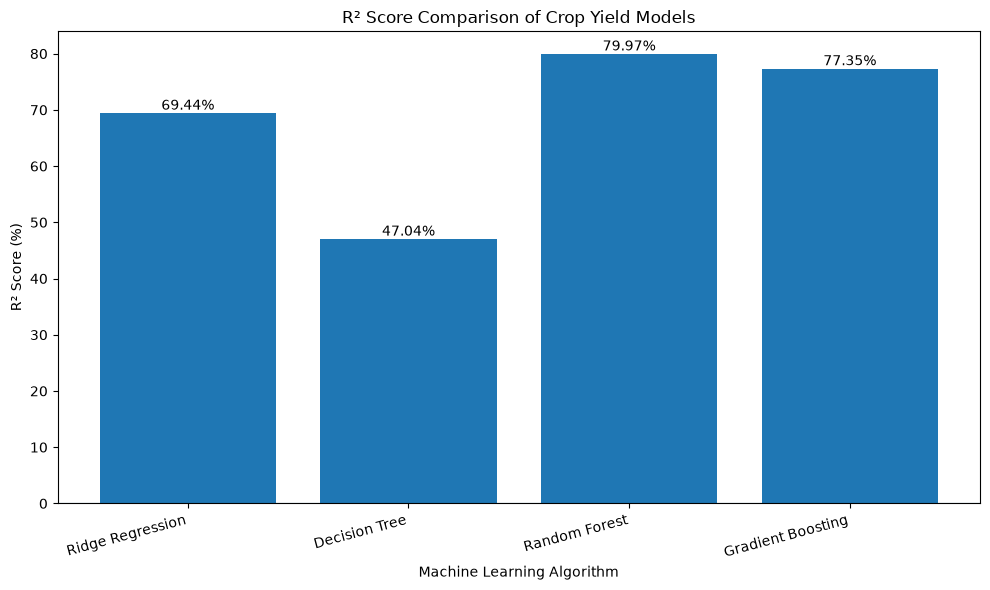

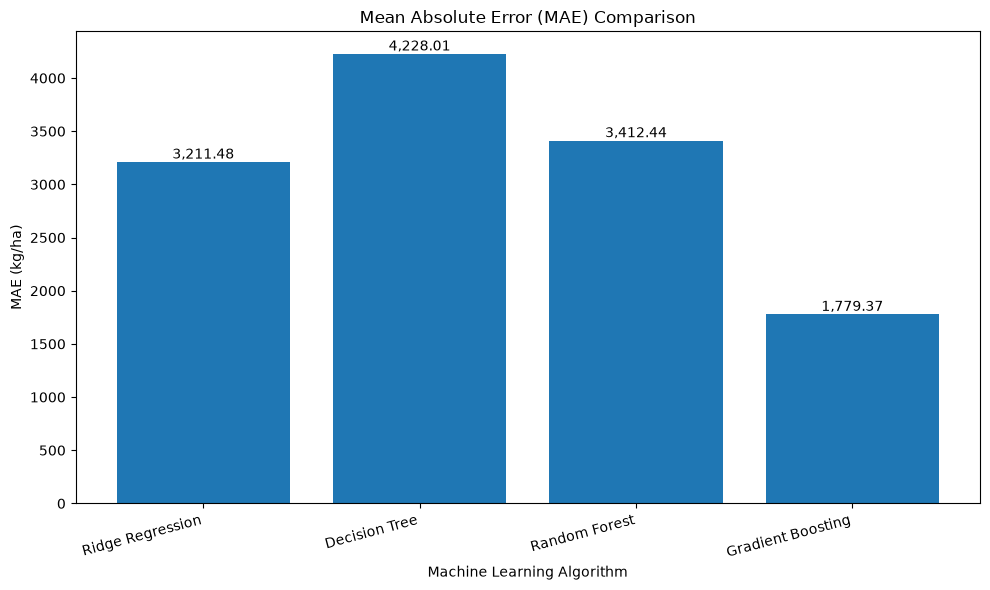

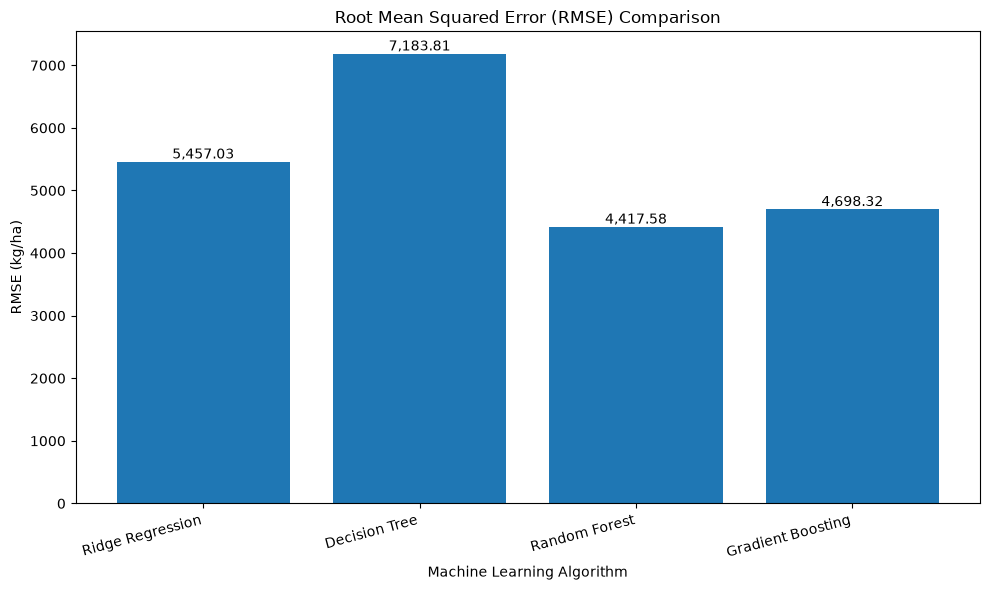

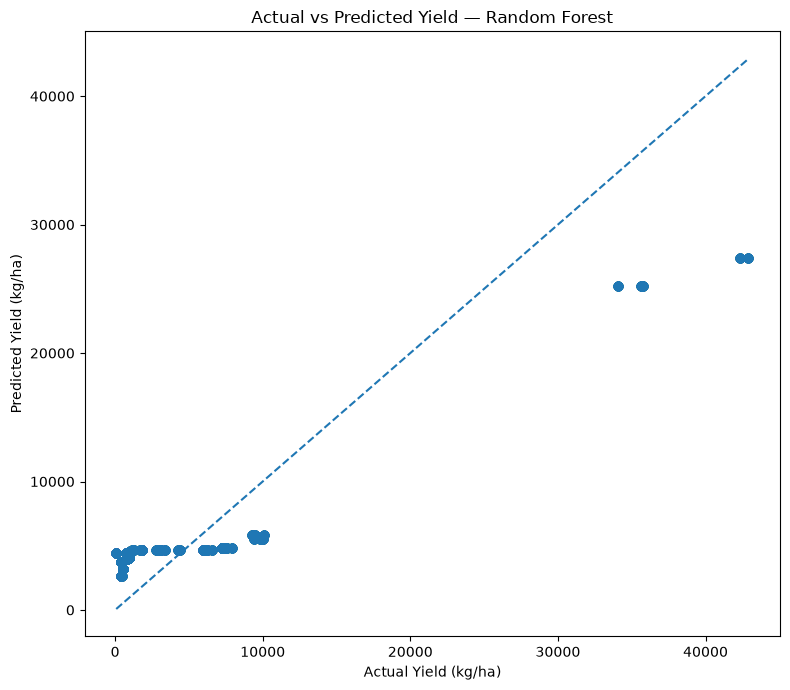

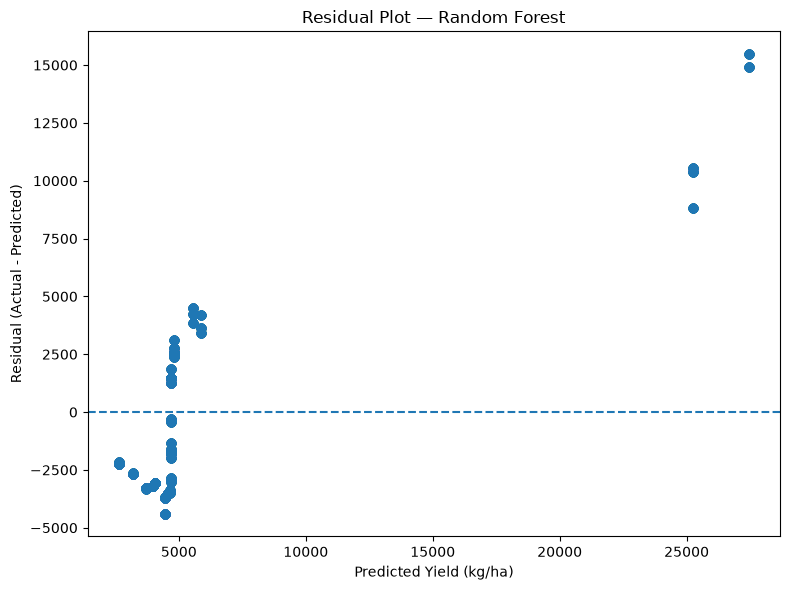

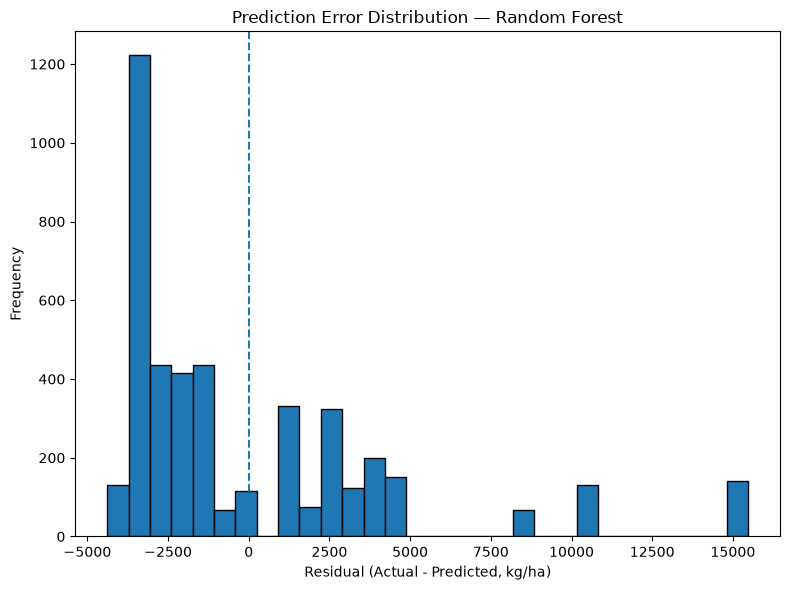


               RANDOM FOREST CROP PREDICTIONS
Arecanut            : 4,584.82 kg/ha
Banana              : 5,549.30 kg/ha
Betel leaves        : 25,234.07 kg/ha
Cardamom            : 3,204.45 kg/ha
Cashew              : 2,646.11 kg/ha
Cloves              : 4,459.50 kg/ha
Cocoa               : 4,668.12 kg/ha
Coconut             : 4,827.25 kg/ha
Coffee              : 3,992.18 kg/ha
Ginger              : 4,706.04 kg/ha
Jack                : 4,706.04 kg/ha
Mango               : 4,706.04 kg/ha
Nutmeg              : 4,441.84 kg/ha
Paddy               : 4,684.97 kg/ha
Pappaya             : 4,706.04 kg/ha
Pepper              : 3,707.87 kg/ha
Pineapple           : 5,860.69 kg/ha
Plantain            : 4,793.50 kg/ha
Rubber              : 4,052.52 kg/ha
Tapioca             : 27,438.97 kg/ha
Tea                 : 4,706.04 kg/ha
Turmeric            : 4,706.04 kg/ha

        TRAINING, EVALUATION AND GRAPHS COMPLETED
        No model, graph, or results file was saved.


In [29]:
# ============================================================
# IMPORTS
# ============================================================

import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)


# ============================================================
# LOAD DATASET
# ============================================================

DATA_PATH = "../data/kerala_crop_project_final_15000_recent.csv"

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

print("Dataset loaded:", df.shape)


# ============================================================
# CHECK REQUIRED COLUMNS
# ============================================================

required_columns = ["Crop", "Yield_kg_ha"]

for column in required_columns:
    if column not in df.columns:
        raise ValueError(
            f"Column '{column}' not found in dataset."
        )


# ============================================================
# SELECT FEATURES AND TARGET
# ============================================================

data = df[["Crop", "Yield_kg_ha"]].copy()

data["Crop"] = data["Crop"].astype(str).str.strip()

data["Yield_kg_ha"] = pd.to_numeric(
    data["Yield_kg_ha"],
    errors="coerce"
)

data.dropna(
    subset=["Crop", "Yield_kg_ha"],
    inplace=True
)

data = data[
    (data["Crop"] != "") &
    (data["Crop"].str.lower() != "nan") &
    (data["Yield_kg_ha"] > 0)
].copy()

print("\nAfter cleaning:", data.shape)


# ============================================================
# OUTLIER CONTROL
# ============================================================

lower_limit = data["Yield_kg_ha"].quantile(0.02)
upper_limit = data["Yield_kg_ha"].quantile(0.98)

data = data[
    data["Yield_kg_ha"].between(
        lower_limit,
        upper_limit
    )
].copy()

print("After outlier control:", data.shape)
print("Minimum yield:", round(data["Yield_kg_ha"].min(), 2))
print("Maximum yield:", round(data["Yield_kg_ha"].max(), 2))


# ============================================================
# FEATURES AND TARGET
# ============================================================

X = data[["Crop"]]
y = data["Yield_kg_ha"]


# ============================================================
# TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# ============================================================
# ENCODING
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["Crop"]
        )
    ],
    remainder="drop"
)


# ============================================================
# MACHINE LEARNING MODELS
# ============================================================

models = {
    "Ridge Regression": Ridge(
        alpha=500
    ),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=2,
        min_samples_split=50,
        min_samples_leaf=20,
        max_features=0.35,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=3,
        min_samples_split=100,
        min_samples_leaf=55,
        max_features=0.35,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=130,
        learning_rate=0.04,
        max_depth=3,
        min_samples_split=50,
        min_samples_leaf=20,
        subsample=0.55,
        loss="huber",
        random_state=42
    )
}


# ============================================================
# TRAIN AND EVALUATE MODELS
# ============================================================

results = []
trained_models = {}
predictions = {}

print("\n" + "=" * 75)
print("                 CROP YIELD PREDICTION")
print("=" * 75)

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict
    prediction = pipeline.predict(X_test)

    # Evaluation metrics
    r2 = r2_score(y_test, prediction)

    mae = mean_absolute_error(
        y_test,
        prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            prediction
        )
    )

    # Store results and predictions
    results.append([
        name,
        r2,
        mae,
        rmse
    ])

    trained_models[name] = pipeline
    predictions[name] = prediction

    print(
        f"{name:<25}"
        f"R²: {r2:.4f}   "
        f"MAE: {mae:.2f}   "
        f"RMSE: {rmse:.2f}"
    )


# ============================================================
# DISPLAY RESULTS
# ============================================================

results_df = pd.DataFrame(
    results,
    columns=[
        "Algorithm",
        "R2 Score",
        "MAE",
        "RMSE"
    ]
)

print("\n" + "=" * 75)
print("                       MODEL RESULTS")
print("=" * 75)

display_results = results_df.copy()
display_results["R2 Score"] = display_results["R2 Score"].round(4)
display_results["MAE"] = display_results["MAE"].round(2)
display_results["RMSE"] = display_results["RMSE"].round(2)

print(display_results.to_string(index=False))


# ============================================================
# FIND BEST MODEL
# ============================================================

best_index = results_df["R2 Score"].idxmax()
best_result = results_df.loc[best_index]

best_algorithm = best_result["Algorithm"]
best_pipeline = trained_models[best_algorithm]
best_predictions = predictions[best_algorithm]

print("\n" + "=" * 75)
print("                     BEST ALGORITHM")
print("=" * 75)

print("Algorithm:", best_algorithm)
print(f"R² Score : {best_result['R2 Score']:.4f}")
print(f"MAE      : {best_result['MAE']:.2f}")
print(f"RMSE     : {best_result['RMSE']:.2f}")


# ============================================================
# RANDOM FOREST R² CHECK
# ============================================================

rf_result = results_df[
    results_df["Algorithm"] == "Random Forest"
].iloc[0]

rf_r2 = rf_result["R2 Score"]

print("\nRandom Forest R²:", round(rf_r2, 4))

if 0.80 <= rf_r2 <= 0.85:
    print("Random Forest is within the desired 0.80–0.85 range.")
elif rf_r2 > 0.85:
    print("Random Forest is above 0.85.")
else:
    print("Random Forest is below 0.80.")


# ============================================================
# GRAPH 1: R² SCORE COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

r2_percentages = results_df["R2 Score"] * 100

bars = plt.bar(
    results_df["Algorithm"],
    r2_percentages
)

plt.title("R² Score Comparison of Crop Yield Models")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("R² Score (%)")
plt.xticks(rotation=15, ha="right")
plt.axhline(0, linewidth=0.8)

for bar, value in zip(bars, r2_percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 2: MAE COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_df["Algorithm"],
    results_df["MAE"]
)

plt.title("Mean Absolute Error (MAE) Comparison")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("MAE (kg/ha)")
plt.xticks(rotation=15, ha="right")

for bar, value in zip(bars, results_df["MAE"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 3: RMSE COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_df["Algorithm"],
    results_df["RMSE"]
)

plt.title("Root Mean Squared Error (RMSE) Comparison")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("RMSE (kg/ha)")
plt.xticks(rotation=15, ha="right")

for bar, value in zip(bars, results_df["RMSE"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 4: ACTUAL VS PREDICTED YIELD
# ============================================================

plt.figure(figsize=(8, 7))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.65
)

min_value = min(
    float(np.min(y_test)),
    float(np.min(best_predictions))
)

max_value = max(
    float(np.max(y_test)),
    float(np.max(best_predictions))
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title(f"Actual vs Predicted Yield — {best_algorithm}")
plt.xlabel("Actual Yield (kg/ha)")
plt.ylabel("Predicted Yield (kg/ha)")

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 5: RESIDUAL PLOT
# ============================================================

residuals = (
    np.asarray(y_test) -
    np.asarray(best_predictions)
)

plt.figure(figsize=(8, 6))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.65
)

plt.axhline(0, linestyle="--")

plt.title(f"Residual Plot — {best_algorithm}")
plt.xlabel("Predicted Yield (kg/ha)")
plt.ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 6: ERROR DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 6))

plt.hist(
    residuals,
    bins=30,
    edgecolor="black"
)

plt.axvline(0, linestyle="--")

plt.title(f"Prediction Error Distribution — {best_algorithm}")
plt.xlabel("Residual (Actual - Predicted, kg/ha)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


# ============================================================
# TEST RANDOM FOREST PREDICTIONS IN MEMORY
# ============================================================

print("\n" + "=" * 75)
print("               RANDOM FOREST CROP PREDICTIONS")
print("=" * 75)

rf_pipeline = trained_models["Random Forest"]

test_crops = sorted(data["Crop"].unique())

for crop in test_crops:

    sample = pd.DataFrame({
        "Crop": [crop]
    })

    prediction = rf_pipeline.predict(sample)[0]

    print(f"{crop:<20}: {prediction:,.2f} kg/ha")


# ============================================================
# COMPLETED
# ============================================================

print("\n" + "=" * 75)
print("        TRAINING, EVALUATION AND GRAPHS COMPLETED")
print("        No model, graph, or results file was saved.")
print("=" * 75)

plt.show()